In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import os

          DATASET LOADING

Dataset loaded successfully!

           DATA CLEANING

Rows before cleaning : 30
Rows after cleaning  : 30
Rows removed         : 0

Columns:
['YearsExperience', 'Salary']

       EXPLORATORY DATA ANALYSIS

1. DATASET SHAPE
----------------------------------------
Total Rows    : 30
Total Columns : 2

First 5 Rows:
   YearsExperience   Salary
0              1.2  39344.0
1              1.4  46206.0
2              1.6  37732.0
3              2.1  43526.0
4              2.3  39892.0


2. DATASET INFORMATION
----------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes

Missing Values:
YearsExperience    0
Salary             0
dtype: int64


3. DESCRIPTIVE S

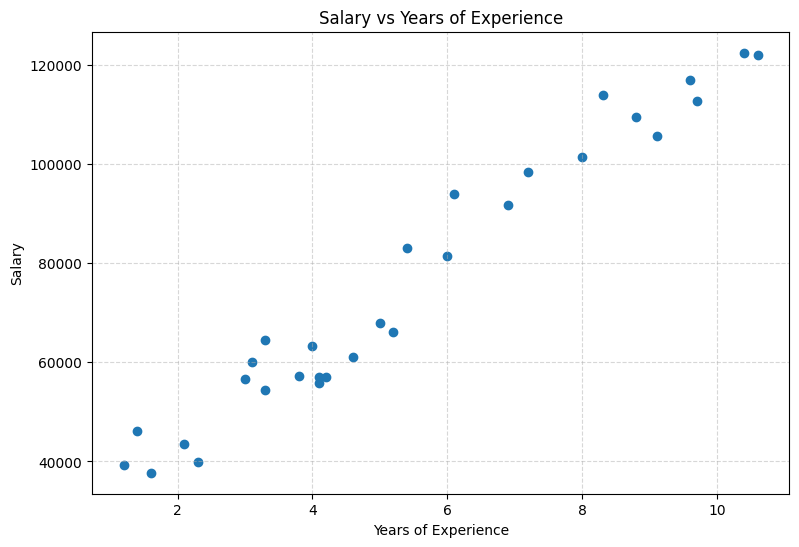


       LINEAR REGRESSION MODEL

Training samples : 24
Testing samples  : 6

Model trained successfully!

Regression Equation:
Salary = 9423.82 × YearsExperience + 24380.20

          MODEL EVALUATION

MAE  : 6286.45
MSE  : 49830096.86
RMSE : 7059.04
R²   : 0.9024

       REGRESSION VISUALIZATIONS



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


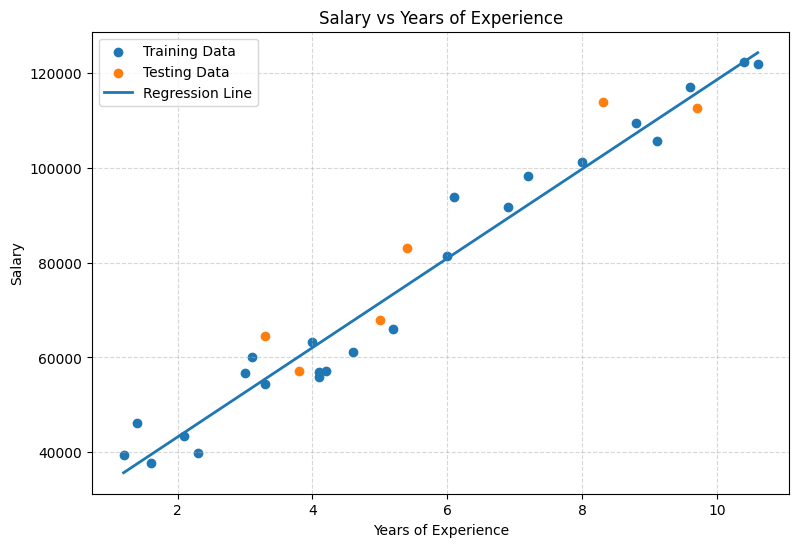

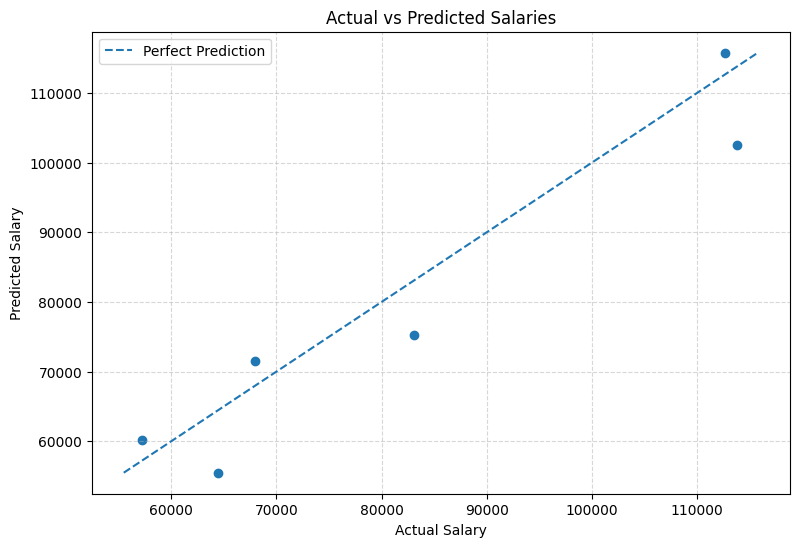

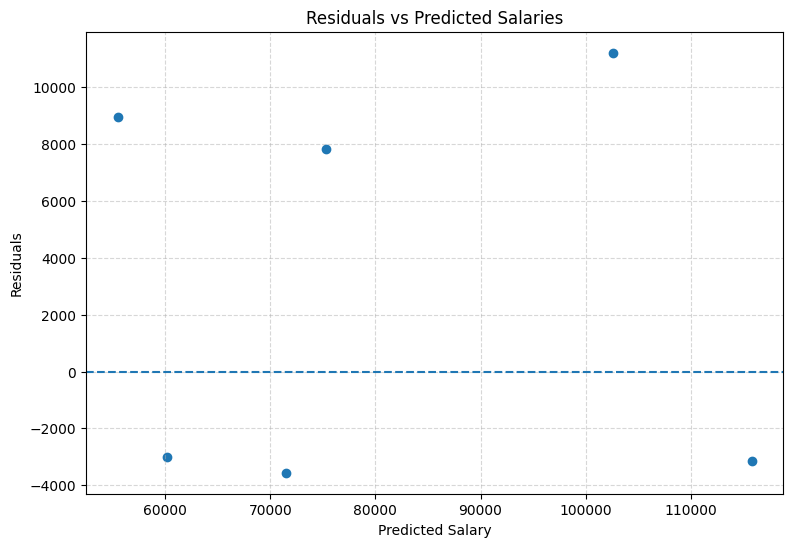

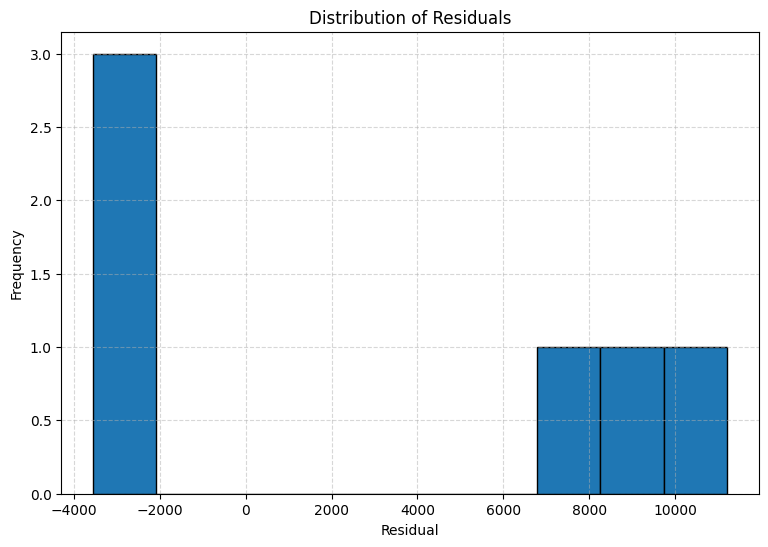


          SALARY PREDICTIONS

Experience: 5.5 years -> Predicted Salary: 76211.19
Experience: 8.0 years -> Predicted Salary: 99770.72
Experience: 10.5 years -> Predicted Salary: 123330.26


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [2]:
# ============================================================
# SALARY PREDICTION USING SIMPLE LINEAR REGRESSION
# GOOGLE COLAB VERSION
# ============================================================

# =========================
# 1. IMPORT LIBRARIES
# =========================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ============================================================
# 2. DATASET LOADING
# ============================================================

def load_dataset():

    print("=========================================")
    print("          DATASET LOADING")
    print("=========================================\n")

    # Dataset uploaded to Colab Files
    dataset_path = "/content/Salary_dataset.csv"

    try:
        df = pd.read_csv(dataset_path)
        print("Dataset loaded successfully!\n")
    except FileNotFoundError:
        print("ERROR: Salary_dataset.csv not found.")
        print("Please upload Salary_dataset.csv using the Files panel.")
        return None

    return df


# ============================================================
# 3. DATA CLEANING
# ============================================================

def clean_dataset(df):

    print("=========================================")
    print("           DATA CLEANING")
    print("=========================================\n")

    # Remove unnecessary index column
    if 'Unnamed: 0' in df.columns:
        df.drop('Unnamed: 0', axis=1, inplace=True)

    # Remove completely empty columns
    df.dropna(axis=1, how='all', inplace=True)

    # Remove rows containing missing values
    before = len(df)
    df.dropna(inplace=True)
    after = len(df)

    print(f"Rows before cleaning : {before}")
    print(f"Rows after cleaning  : {after}")
    print(f"Rows removed         : {before - after}\n")

    print("Columns:")
    print(df.columns.tolist())

    return df


# ============================================================
# 4. EXPLORATORY DATA ANALYSIS
# ============================================================

def explore_dataset(df):

    print("\n=========================================")
    print("       EXPLORATORY DATA ANALYSIS")
    print("=========================================\n")

    # ------------------------------------
    # Dataset Shape
    # ------------------------------------

    print("1. DATASET SHAPE")
    print("-" * 40)

    print(f"Total Rows    : {df.shape[0]}")
    print(f"Total Columns : {df.shape[1]}")

    # ------------------------------------
    # First 5 Rows
    # ------------------------------------

    print("\nFirst 5 Rows:")
    print(df.head())

    # ------------------------------------
    # Dataset Information
    # ------------------------------------

    print("\n\n2. DATASET INFORMATION")
    print("-" * 40)

    df.info()

    # ------------------------------------
    # Missing Values
    # ------------------------------------

    print("\nMissing Values:")
    print(df.isnull().sum())

    # ------------------------------------
    # Descriptive Statistics
    # ------------------------------------

    print("\n\n3. DESCRIPTIVE STATISTICS")
    print("-" * 40)

    print(df.describe().T)

    # ------------------------------------
    # Skewness
    # ------------------------------------

    print("\n\n4. SKEWNESS")
    print("-" * 40)

    print(df.skew())

    # ------------------------------------
    # Kurtosis
    # ------------------------------------

    print("\n\nKURTOSIS")
    print("-" * 40)

    print(df.kurtosis())

    # ------------------------------------
    # Correlation
    # ------------------------------------

    print("\n\n5. CORRELATION ANALYSIS")
    print("-" * 40)

    correlation_matrix = df.corr()

    print(correlation_matrix)

    # Correlation between experience and salary
    corr_value = df['YearsExperience'].corr(df['Salary'])

    print(
        f"\nCorrelation between YearsExperience "
        f"and Salary: {corr_value:.4f}"
    )

    if corr_value > 0.8:
        print(
            "Interpretation: Very strong positive correlation. "
            "Salary tends to increase as experience increases."
        )

    elif corr_value > 0.5:
        print(
            "Interpretation: Moderate positive correlation."
        )

    elif corr_value > 0:
        print(
            "Interpretation: Weak positive correlation."
        )

    else:
        print(
            "Interpretation: Negative or no correlation."
        )


# ============================================================
# 5. VISUALIZE DATASET
# ============================================================

def visualize_dataset(df):

    print("\n=========================================")
    print("       DATASET VISUALIZATION")
    print("=========================================\n")

    # Salary vs Experience
    plt.figure(figsize=(9, 6))

    plt.scatter(
        df['YearsExperience'],
        df['Salary']
    )

    plt.title("Salary vs Years of Experience")
    plt.xlabel("Years of Experience")
    plt.ylabel("Salary")
    plt.grid(True, linestyle='--', alpha=0.5)

    plt.show()


# ============================================================
# 6. TRAIN LINEAR REGRESSION MODEL
# ============================================================

def train_model(df):

    print("\n=========================================")
    print("       LINEAR REGRESSION MODEL")
    print("=========================================\n")

    # Feature
    X = df[['YearsExperience']]

    # Target
    y = df['Salary']

    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42
    )

    print(f"Training samples : {len(X_train)}")
    print(f"Testing samples  : {len(X_test)}")

    # Create model
    model = LinearRegression()

    # Train model
    model.fit(X_train, y_train)

    print("\nModel trained successfully!")

    # Model equation
    slope = model.coef_[0]
    intercept = model.intercept_

    print("\nRegression Equation:")
    print(
        f"Salary = {slope:.2f} × YearsExperience + "
        f"{intercept:.2f}"
    )

    return model, X_train, X_test, y_train, y_test


# ============================================================
# 7. MODEL EVALUATION
# ============================================================

def evaluate_model(model, X_test, y_test):

    print("\n=========================================")
    print("          MODEL EVALUATION")
    print("=========================================\n")

    # Predictions
    y_pred = model.predict(X_test)

    # Metrics
    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, y_pred)

    print(f"MAE  : {mae:.2f}")
    print(f"MSE  : {mse:.2f}")
    print(f"RMSE : {rmse:.2f}")
    print(f"R²   : {r2:.4f}")

    return y_pred, mae, mse, rmse, r2


# ============================================================
# 8. REGRESSION VISUALIZATION
# ============================================================

def regression_visualization(
    model,
    X_train,
    X_test,
    y_train,
    y_test,
    y_pred
):

    print("\n=========================================")
    print("       REGRESSION VISUALIZATIONS")
    print("=========================================\n")

    # --------------------------------------------------------
    # Plot 1: Regression Line
    # --------------------------------------------------------

    plt.figure(figsize=(9, 6))

    plt.scatter(
        X_train,
        y_train,
        label='Training Data'
    )

    plt.scatter(
        X_test,
        y_test,
        label='Testing Data'
    )

    # Sort values so regression line is smooth
    X_sorted = np.sort(X_train.values, axis=0)

    plt.plot(
        X_sorted,
        model.predict(X_sorted),
        label='Regression Line',
        linewidth=2
    )

    plt.title("Salary vs Years of Experience")
    plt.xlabel("Years of Experience")
    plt.ylabel("Salary")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)

    plt.show()


    # --------------------------------------------------------
    # Plot 2: Actual vs Predicted
    # --------------------------------------------------------

    plt.figure(figsize=(9, 6))

    plt.scatter(
        y_test,
        y_pred
    )

    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())

    plt.plot(
        [min_val, max_val],
        [min_val, max_val],
        linestyle='--',
        label='Perfect Prediction'
    )

    plt.title("Actual vs Predicted Salaries")
    plt.xlabel("Actual Salary")
    plt.ylabel("Predicted Salary")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)

    plt.show()


    # --------------------------------------------------------
    # Plot 3: Residuals vs Predicted
    # --------------------------------------------------------

    residuals = y_test - y_pred

    plt.figure(figsize=(9, 6))

    plt.scatter(
        y_pred,
        residuals
    )

    plt.axhline(
        y=0,
        linestyle='--'
    )

    plt.title("Residuals vs Predicted Salaries")
    plt.xlabel("Predicted Salary")
    plt.ylabel("Residuals")

    plt.grid(True, linestyle='--', alpha=0.5)

    plt.show()


    # --------------------------------------------------------
    # Plot 4: Distribution of Residuals
    # --------------------------------------------------------

    plt.figure(figsize=(9, 6))

    plt.hist(
        residuals,
        bins=10,
        edgecolor='black'
    )

    plt.title("Distribution of Residuals")
    plt.xlabel("Residual")
    plt.ylabel("Frequency")

    plt.grid(True, linestyle='--', alpha=0.5)

    plt.show()


# ============================================================
# 9. NEW SALARY PREDICTION
# ============================================================

def predict_new_salary(model):

    print("\n=========================================")
    print("          SALARY PREDICTIONS")
    print("=========================================\n")

    # New experience values
    new_experience = np.array([
        [5.5],
        [8.0],
        [10.5]
    ])

    # Predict salaries
    new_salary_pred = model.predict(new_experience)

    for exp, salary in zip(
        new_experience.flatten(),
        new_salary_pred
    ):

        print(
            f"Experience: {exp:.1f} years "
            f"-> Predicted Salary: {salary:.2f}"
        )


# ============================================================
# 10. MAIN PROGRAM
# ============================================================

def main():

    # Load dataset
    df = load_dataset()

    if df is None:
        return

    # Clean dataset
    df = clean_dataset(df)

    # EDA
    explore_dataset(df)

    # Basic visualization
    visualize_dataset(df)

    # Train model
    model, X_train, X_test, y_train, y_test = train_model(df)

    # Evaluate model
    y_pred, mae, mse, rmse, r2 = evaluate_model(
        model,
        X_test,
        y_test
    )

    # Regression visualizations
    regression_visualization(
        model,
        X_train,
        X_test,
        y_train,
        y_test,
        y_pred
    )

    # Predict new salaries
    predict_new_salary(model)


# ============================================================
# RUN PROGRAM
# ============================================================

main()

Inference

The dataset contains 30 observations with two variables: YearsExperience and Salary. There are no missing values or removed records, so the dataset is complete and suitable for modeling.

The exploratory analysis shows that YearsExperience and Salary have a very strong positive correlation of 0.9782, indicating that salary generally increases as professional experience increases. Both variables have relatively low positive skewness, while their negative kurtosis suggests a flatter distribution compared with a normal distribution.

A Simple Linear Regression model was trained using 80% of the data (24 samples), with the remaining 20% (6 samples) used for testing. The resulting regression equation is:

$$ \boxed{Salary = 9423.82 \times YearsExperience + 24380.20} $$

This means that, within this dataset, each additional year of experience is associated with an estimated ₹9,423.82 increase in annual salary (assuming the salary units in the dataset are interpreted as INR).

The model achieved an R² score of 0.9024, meaning approximately 90.24% of the variation in salary in the test set is explained by YearsExperience through this linear model. The MAE of 6,286.45 means that the model's predictions differ from the actual salaries by about 6,286 salary units on average, while the RMSE of 7,059.04 indicates the typical prediction error while giving greater weight to larger errors.

The regression and residual plots can be used to visually assess model fit. The strong upward trend and high R² indicate that a linear relationship is a reasonable approximation for this dataset. However, the dataset is very small (only 30 observations), so the model's performance should not be generalized too broadly to real-world salary prediction.

Using the trained model, the predicted salaries are:

Experience	Predicted Salary
5.5 years	76,211.19
8.0 years	99,770.72
10.5 years	123,330.26
Overall inference

Years of professional experience is a strong predictor of salary in this dataset. The Simple Linear Regression model explains approximately 90.24% of the salary variation on the test data and provides reasonably accurate salary estimates. However, salary is influenced by many other factors—such as job role, location, education, skills, industry, and company—so a model using only experience should be considered a simplified prediction model rather than a complete salary estimation system.